# W11B B · Mel을 만들고, 파형으로 듣고, 실제 응답까지 연결
2026-11-11 ·9.3~9.7. 이 노트북만 새 사본에서 실행할 수 있습니다.
**현재 실행**: 실제 SpeechT5·HiFiGAN·Whisper·문자 모델, 소형 RVQ·확산 학습 계산.
**사전 실제 실행 기록 분석**: MusicGen 두 조건, EnCodec, AudioDiffusion. 모델·seed·shape·시간을 manifest에서 확인합니다. 기록을 현재 생성으로 표시하지 않습니다.
CPU 기본 경로는 API 키·개인 음성·유료 GPU가 필요 없습니다. 다운로드는 최초 수분이 걸릴 수 있습니다. 아래 **실제 decoder 본문**과 종료 함수를 수정하면 합성·앱 결과가 함께 바뀝니다.


In [ ]:
#@title 설치와 공개 샘플 준비 { display-mode: "form" }
import sys, subprocess, os, json, math, re, unicodedata, uuid
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError
PUBLIC_REF='2026-fall-w11b-r1'
local=Path('src/pyproject.toml').is_file()
needed={'luna-genai':'0.1.19','scipy':'1.18.1','librosa':'1.0.0','soundfile':'0.14.0','sentencepiece':'0.2.3'}
try: ready=all(version(name)==expected for name,expected in needed.items())
except PackageNotFoundError: ready=False
if not ready:
    if 'luna_genai' in sys.modules: raise RuntimeError('런타임을 재시작한 뒤 첫 셀부터 실행하세요.')
    package=str(Path('src').resolve())+'[audio]' if local else 'luna-genai[audio] @ '+'git+https://github.com/lunalab-ai/genAI.git@'+PUBLIC_REF+'#subdirectory=src'
    subprocess.run([sys.executable,'-m','pip','install','-q']+(['-e'] if local else [])+[package],check=True)
if local: sys.path.insert(0,str(Path('src').resolve()))  # editable .pth is normally read at kernel startup
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt, soundfile as sf
from IPython.display import display, Audio
from luna_genai.audio_core import load_audio_sample,asset_directory
from luna_genai.audio_models import recognize,synthesize,load_asr,load_tts
torch.set_num_threads(4)
sample=load_audio_sample(); wave=sample['waveform']; fs=sample['sampling_rate']
RUN_ID=uuid.uuid4().hex; IN_COLAB='COLAB_RELEASE_TAG' in os.environ
print('Python',sys.version.split()[0],'luna-genai',version('luna-genai'),'CPU',not torch.cuda.is_available(),'run',RUN_ID)
print('공개 샘플',len(wave),fs,len(wave)/fs,sample['reference'])
display(Audio(wave,rate=fs))


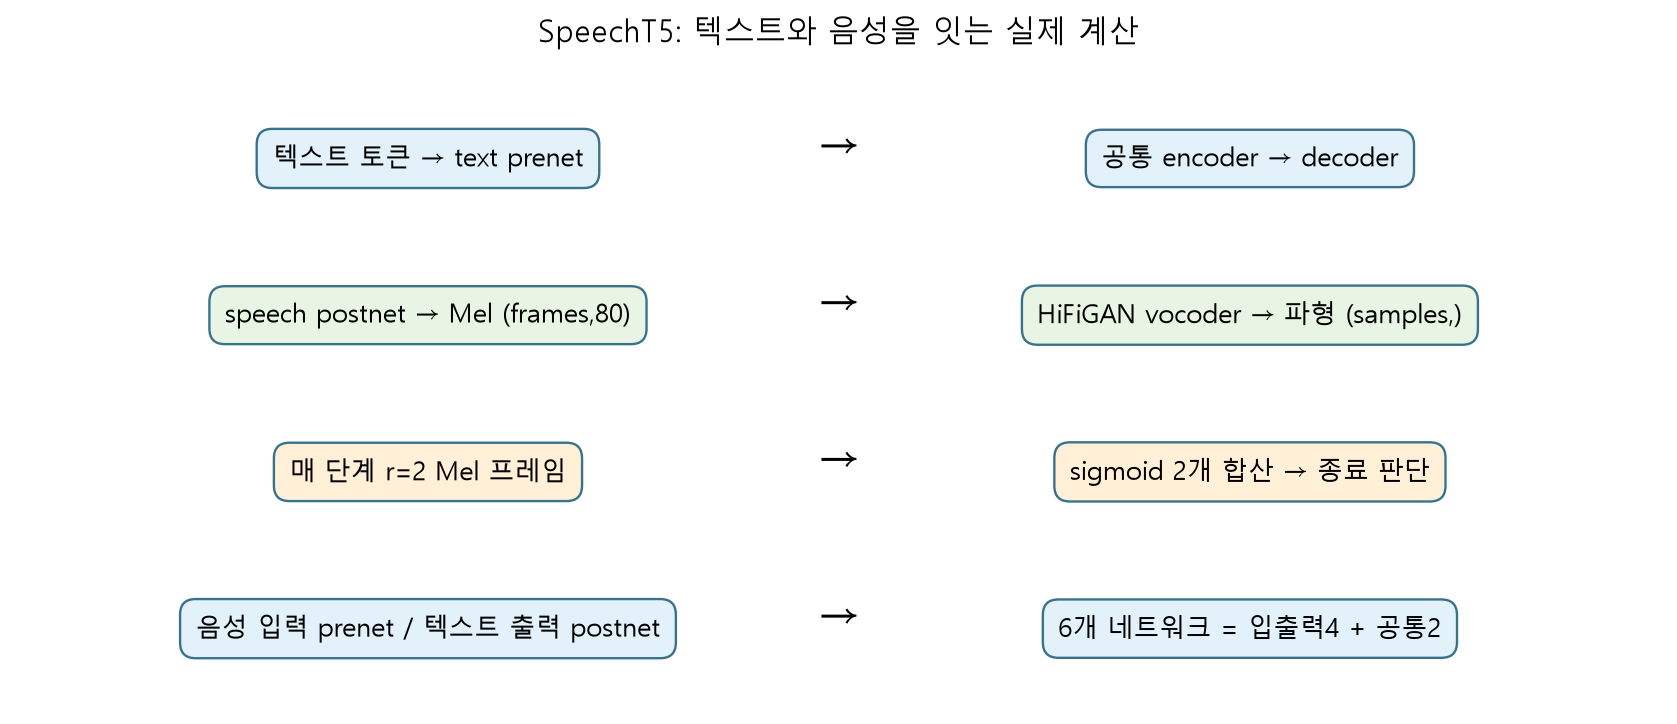

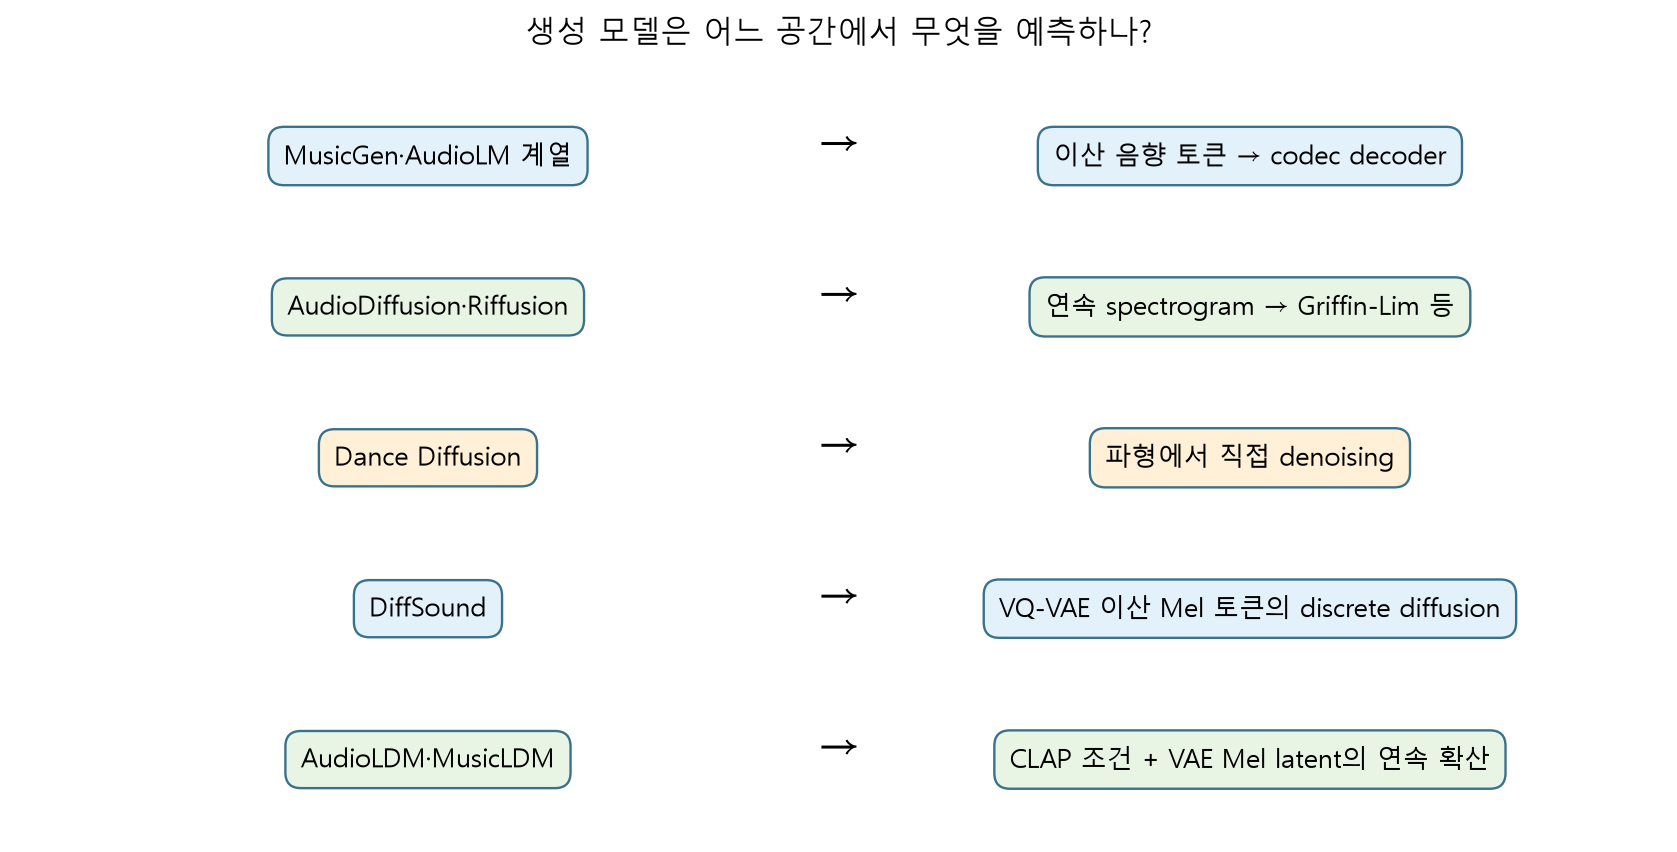


[Figure source](https://raw.githubusercontent.com/lunalab-ai/genAI/2026-fall-w11b-r1/course/notion/w11b/assets/09-tts.png) · [Figure source](https://raw.githubusercontent.com/lunalab-ai/genAI/2026-fall-w11b-r1/course/notion/w11b/assets/12-generators.png)


## 1. 실제 음성 생성 루프를 펼칩니다
텍스트 prenet → 공통 encoder/decoder → speech postnet(Mel) → HiFiGAN(파형).
한 decoder 단계에서 r=2 Mel 프레임이 나옵니다. 현재 구현은 sigmoid 두 값의 **합산 종료점수**를 threshold와 비교합니다. threshold는 vocoder 인자가 아닙니다. 큰 값은 반복·최대 길이 종료를 유발할 수 있습니다.
아래는 Hugging Face Apache2 구현에서 단일 샘플 경로를 추린 수업용 코드입니다. 배치 처리·attention 출력은 생략했고 종료 기록과 함수 주입을 추가했습니다. 모델의 실제 encoder/decoder 가중치를 사용합니다.


In [ ]:
def stop_rule(score, threshold=.5):
    """현재 SpeechT5의 합산 stop score를 기준값과 비교한다. 확률 자체가 아님.

    score는 reduction_factor개 sigmoid 출력의 합, 기본 r=2이면0..2.
    비교는 >=. 이 함수를 실제 decode loop에 전달하여 수정이 결과에 반영된다.
    """
    return bool(float(score) >= float(threshold))


In [ ]:
def decode_speecht5(model, input_ids, speaker_embedding, threshold=.5, max_steps=240, stop_fn=stop_rule):
    """One-example actual autoregressive Mel loop, exposing every stop decision.

    Input IDs (1,L), speaker (1,512); output Mel (frames,80), trace/list.
    max_steps is decoder iterations, each emitting reduction_factor frames.
    SpeechT5 prenet uses dropout during inference; reset seed when comparing.
    stop score is SUM of r sigmoid outputs (r=2), not a single probability.
    This educational batch=1 path omits beam/attention/batched stopping.
    """
    if input_ids.ndim!=2 or input_ids.shape[0]!=1: raise ValueError('Single example only')
    if not 1<=int(max_steps)<=240: raise ValueError('max_steps must be 1..240')
    mask=(input_ids!=model.config.pad_token_id).int()
    hidden=model.speecht5.encoder(input_values=input_ids,attention_mask=mask,return_dict=True).last_hidden_state
    r=model.config.reduction_factor; m=model.config.num_mel_bins
    sequence=hidden.new_zeros(1,1,m); past=None; spectra=[]; trace=[]
    for step in range(1,int(max_steps)+1):
        pre=model.speecht5.decoder.prenet(sequence,speaker_embedding)
        out=model.speecht5.decoder.wrapped_decoder(hidden_states=pre[:,-1:],attention_mask=None,
            encoder_hidden_states=hidden,encoder_attention_mask=mask,
            past_key_values=past,use_cache=True,return_dict=True)
        last=out.last_hidden_state.squeeze(1); past=out.past_key_values
        spectrum=model.speech_decoder_postnet.feat_out(last).view(1,r,m)
        spectra.append(spectrum)
        sequence=torch.cat((sequence,spectrum[:,-1:,:]),dim=1)
        probabilities=torch.sigmoid(model.speech_decoder_postnet.prob_out(last))
        score=float(probabilities.sum())
        stopped=bool(stop_fn(score,threshold))
        trace.append(dict(step=step,frames=step*r,score=score,components=probabilities[0].tolist(),
                          reason='threshold' if stopped else ('limit' if step==int(max_steps) else 'continue')))
        if stopped: break
    mel=model.speech_decoder_postnet.postnet(torch.cat(spectra,dim=1))[0]
    return mel,trace


In [ ]:
results=[]
for threshold in [.5,1.0]:
    result=synthesize('We can hear the model.',sample['speaker_embedding'],threshold,7,
                      decoder_fn=decode_speecht5,stop_fn=stop_rule)
    result['readback']=recognize(result['waveform'],16000)['text']
    results.append(result)
    display(Audio(result['waveform'],rate=16000))
    print('threshold',threshold,'Mel',result['mel'].shape,'seconds',len(result['waveform'])/16000,'readback',result['readback'])
display(pd.DataFrame(results[0]['trace']).tail())
plt.figure(figsize=(8,3))
for r in results:plt.plot([x['step'] for x in r['trace']],[x['score'] for x in r['trace']],label=str(r['threshold']))
plt.xlabel('decoder step');plt.ylabel('sum stop score');plt.legend();plt.show()
# 실제 callback 사용 확인
short=synthesize('We can hear the model.',sample['speaker_embedding'],.5,7,decoder_fn=decode_speecht5,stop_fn=lambda score,t: True)
assert len(short['trace'])==1 and short['mel'].shape[0]==2
my_stop_rule=None


### 9B1 · 종료 규칙을 수정하고 근거를 남기세요
`stop_rule`에서 기준 비교를 바꾸거나 최소 단계 조건을 decoder에 추가하고 같은 문장·seed로 재실행하세요. Mel 프레임 수·파형 길이·읽어 준 문장을 비교하세요. 점수1.1은 확률110%인가요?
힌트: 기본 r=2개의 sigmoid 합입니다. 변경 전 원본을 보관하고 앱에도 수정 함수를 전달합니다. 품질 평가는 청취와 별도로 기록하세요.


## 2. 연속 벡터를 여러 정수 ID로: RVQ
각 단계가 잔차에 가장 가까운 벡터를 고르고 남은 차이를 다음 단계로 보냅니다. 아래는 원리용2차원 RVQ입니다. EnCodec 신경 encoder/decoder 전체를 재현한 모델은 아닙니다.


In [ ]:
def residual_quantize(vector, codebooks):
    """소형 RVQ 원리 계산. 각 codebook (K,D)에서 잔차의 최근접 벡터 선택.

    vector (D,), codebooks list. 반환 codes/list, reconstructed(D,),
    residual(D,), mse(float), trace/list. 사전학습 EnCodec 전체 구현/학습은 아니다.
    """
    original = np.asarray(vector, dtype=float)
    if original.ndim != 1 or not original.size or not np.isfinite(original).all() or not codebooks:
        raise ValueError('Use a finite vector and at least one codebook')
    residual, reconstructed = original.copy(), np.zeros_like(original)
    codes, trace = [], []
    for stage, book in enumerate(codebooks):
        book = np.asarray(book, dtype=float)
        if book.ndim != 2 or book.shape[1] != len(original) or not len(book) or not np.isfinite(book).all():
            raise ValueError('Each codebook must have shape (entries,features)')
        distances = ((book-residual)**2).sum(axis=1)
        code = int(np.argmin(distances))
        reconstructed += book[code]
        residual -= book[code]
        codes.append(code)
        trace.append(dict(stage=stage, code=code, vector=book[code].tolist(), residual=residual.tolist()))
    return dict(codes=codes, reconstructed=reconstructed, residual=residual,
                mse=float(np.mean((original-reconstructed)**2)), trace=trace)


In [ ]:
books=[np.array([[0,0],[1,1]]),np.array([[0,0],[.5,0]])]
toy=residual_quantize([1.7,1.1],books)
display(pd.DataFrame(toy['trace']));print('reconstruction',toy['reconstructed'],'MSE',toy['mse'])
directory=asset_directory();records=sample['manifest']
archive=np.load(str(directory.joinpath('codec.npz')),allow_pickle=False)
print('actual record arrays',[(k,archive[k].shape) for k in archive.files]);print(records['codec'])
display(Audio(filename=str(directory.joinpath('codec-reconstruction.wav'))))
my_codes=None;my_mse=None


### 9B2 · 새 벡터를 양자화하세요
같은 두 codebook에서 z=[1.4,.9]의 첫 선택·잔차·두 번째 선택·최종 재구성·MSE를 계산한 후 실행하세요. 실제 EnCodec 기록의4×100은 무슨 축인가요?


## 3. MusicGen·오디오 확산의 실제 기록 비교
같은 seed7, MusicGen100새토큰, 두 텍스트 조건의 실제 사전 생성 파일입니다. AudioDiffusion은10steps 무조건 생성 기록입니다. 품질 경쟁·현재 실행으로 해석하지 않습니다.
AudioLM은 의미 토큰과 음향 토큰을 계층적으로 연결하며 MusicLM은 MuLan 음악-텍스트 임베딩을 사용합니다. MusicGen은 텍스트 조건의 codec token 예측입니다. Bark·AudioGen은 음성/일반 소리 생성의 서로 다른 설계입니다. 모델 이름을 같은 출력 품질로 묶지 마세요.


In [ ]:
display(pd.DataFrame(records['music']))
for filename in ['music-0.wav','music-1.wav','audio-diffusion.wav']:
    print('PREVIOUS-REAL-RECORD',filename)
    display(Audio(filename=str(directory.joinpath(filename))))
print(records['diffusion'])
assert all(r['samples']>0 and r['seconds']>0 for r in records['music'])


### 9B3 · 같은 축으로 비교할 수 있나요?
두 MusicGen 기록의 고정 조건·바꾼 조건·관찰 결과·일반화 한계를 적으세요. CLAP 유사도 하나로 자연스러움과 저작권을 모두 판정할 수 있나요? AudioLDM은 CLAP 벡터 자체를 denoise하나요?


## 4. 장말 도전3의 작은 학습 경로
실제 Dance Diffusion 대형 모델 학습 대신, 이 셀은 **1차원 오디오의 noise 예측 학습 원리**를 CPU에서 실행합니다. 학습 데이터는 직접 만든 사인파입니다. 학습되는 가중치·noisy input·정답 noise·MSE를 확인합니다. Dance Diffusion 재현이나 음악 품질 결과로 표시하지 않습니다. 전체 프로젝트의 데이터 권리·분할·평가 설계는 지도서에 별도로 있습니다.


In [ ]:
torch.manual_seed(7)
clean=torch.sin(torch.linspace(0,8*torch.pi,512))[None,None,:].repeat(8,1,1)
net=torch.nn.Sequential(torch.nn.Conv1d(1,16,5,padding=2),torch.nn.SiLU(),torch.nn.Conv1d(16,1,5,padding=2))
optimizer=torch.optim.Adam(net.parameters(),lr=.01)
fixed_noise=torch.randn_like(clean);noisy=.8*clean+.6*fixed_noise
losses=[];before=[p.detach().clone() for p in net.parameters()]
for step in range(20):
    predicted=net(noisy)
    loss=(predicted-fixed_noise).square().mean()
    optimizer.zero_grad();loss.backward();optimizer.step();losses.append(float(loss.detach()))
assert np.isfinite(losses).all() and losses[-1]<losses[0]
assert any(not torch.equal(a,b) for a,b in zip(before,net.parameters()))
print('toy noise prediction MSE',losses[0],losses[-1])
plt.plot(losses);plt.xlabel('training step');plt.ylabel('fixed toy batch noise MSE');plt.show()


### 9B4 · loss가 낮아졌다는 말의 범위
위 optimizer는 어떤 가중치를 바꾸나요? 고정 batch의 loss 감소가 새로운 음악 생성 품질을 증명하나요? 새 noise·주파수·화자로 평가하려면 무엇을 분리해야 하나요?


## 5. 9.6 실제 누적 음성 프로젝트
입력 음성 → 실제 Whisper 문자 → 실제 Qwen 문자 모델의 새 continuation → 수정한 SpeechT5 루프 → HiFiGAN 파형입니다. 기본 언어 모델은 교육용 소형 base 모델로 답의 정확성을 보장하지 않습니다. 민감한 음성은 올리지 마세요.
실제 앱 API와 다운로드 내용을 아래에서 먼저 확인합니다. 현재 UI 실행은 Colab에서 이어집니다. A노트북을 실행한 적이 없어도 동작합니다.


In [ ]:
from luna_genai.audio_core import whisper_logmel,ctc_decode,text_error
from luna_genai.audio_app import route_image_request
import csv,tempfile


In [ ]:
def build_audio_app(feature_fn=whisper_logmel,decode_fn=ctc_decode,error_fn=text_error,
                    decoder_fn=decode_speecht5,stop_fn=stop_rule,image_fn=route_image_request):
    import gradio as gr
    sample=load_audio_sample()
    def transcribe(audio,reference):
        if audio is None: rate,wave=sample['sampling_rate'],sample['waveform']
        else: rate,wave=audio
        result=recognize(wave,rate,'whisper',feature_fn=feature_fn)
        score=error_fn(reference,result['text'])
        return result['text'],dict(WER=score['rate'],counts=score['counts'],input_shape=result['input_shape'])
    def speak(text,threshold,seed):
        result=synthesize(text,sample['speaker_embedding'],threshold,int(seed),decoder_fn=decoder_fn,stop_fn=stop_fn)
        folder=Path(tempfile.mkdtemp(prefix='w11b-'))
        wav=folder/'speech.wav'; sf.write(wav,result['waveform'],16000)
        report=folder/'settings.json'; report.write_text(json.dumps({k:v for k,v in result.items() if k not in ('waveform','mel')},ensure_ascii=False,indent=2),encoding='utf-8')
        trace=folder/'stop-trace.csv'
        with trace.open('w',newline='',encoding='utf-8') as handle:
            writer=csv.DictWriter(handle,fieldnames=['step','frames','score','components','reason']);writer.writeheader();writer.writerows(result['trace'])
        return (16000,result['waveform']),str(wav),str(report),str(trace)
    def respond(audio):
        if audio is None: rate,wave=sample['sampling_rate'],sample['waveform']
        else: rate,wave=audio
        recognized=recognize(wave,rate,'whisper',feature_fn=feature_fn)['text']
        from luna_genai.model import LanguageModelLab
        continuation=LanguageModelLab(device='cpu').generate('Question: '+recognized+'\nAnswer:',strategy='greedy',max_new_tokens=20)
        spoken=continuation.strip()[:160]
        if not spoken: raise RuntimeError('Text model returned empty continuation')
        outputs=speak(spoken,.5,7)
        return recognized,spoken,*outputs
    with gr.Blocks(title='W11B 오디오 원리 실험실') as app:
        gr.Markdown('# 듣기 → 문자 → 새 응답 → 말하기\n영어 소형 모델 실험입니다. 빈 입력은 공개 샘플을 사용합니다. 개인 음성 업로드는 선택이며 공유 앱에는 민감한 음성을 넣지 마세요.')
        audio=gr.Audio(type='numpy',label='입력 음성 (비우면 공개 샘플)')
        reference=gr.Textbox(value=sample['reference'],label='평가 기준 문장')
        asr_button=gr.Button('음성 인식·오류율 계산'); transcript=gr.Textbox(label='인식 결과'); metric=gr.JSON(label='실제 계산')
        asr_button.click(transcribe,[audio,reference],[transcript,metric],api_name='transcribe')
        text=gr.Textbox(value='We can hear the model.',label='합성할 영어 문장')
        threshold=gr.Slider(.1,1.5,value=.5,step=.1,label='합산 종료점수 기준'); seed=gr.Number(value=7,precision=0,label='seed')
        speech_button=gr.Button('Mel 생성 → 파형 듣기'); generated=gr.Audio(label='실제 생성 음성')
        wav=gr.File(label='WAV'); report=gr.File(label='설정 JSON'); trace=gr.File(label='종료점수 CSV')
        speech_button.click(speak,[text,threshold,seed],[generated,wav,report,trace],api_name='synthesize')
        response_button=gr.Button('실제 문자 모델 응답까지 연결'); answer=gr.Textbox(label='문자 모델의 새 continuation (정확한 답변 보장 없음)')
        response_button.click(respond,[audio],[transcript,answer,generated,wav,report,trace],api_name='respond')
        gr.Markdown('## 이전 이미지 기능 연결 · 선택 확장\n고정 수업 이미지에 실제 소형 denoiser를 실행합니다. 새 SD 텍스트 이미지 생성이 아닙니다.')
        strength=gr.Slider(0,1,value=.5,step=.25,label='이미지 편집 strength')
        image_button=gr.Button('이전 이미지 모듈 분기 실행');image=gr.Image(label='실제 소형 편집 이미지')
        image_trace=gr.Dataframe(label='denoising 기록');image_settings=gr.JSON(label='이미지 실행 조건')
        image_button.click(image_fn,[strength],[image,image_trace,image_settings],api_name='image_branch')
    app.w11b_callbacks=dict(transcribe=transcribe,speak=speak,respond=respond,image_branch=image_fn)
    return app


In [ ]:
app=build_audio_app(decoder_fn=decode_speecht5,stop_fn=stop_rule)
api_outputs=app.w11b_callbacks['speak']('We can hear the model.',.5,7)
response=app.w11b_callbacks['respond'](None)
print('recognized',response[0]);print('NEW TEXT MODEL CONTINUATION',response[1])
display(Audio(response[2][1],rate=response[2][0]))
for filename in response[3:]:
    assert Path(filename).is_file() and Path(filename).stat().st_size>0
    print('download',Path(filename).name,Path(filename).stat().st_size)
settings=json.loads(Path(response[4]).read_text(encoding='utf-8'))
assert settings['mode']=='current-real-inference' and settings['text']==response[1]
image_result=app.w11b_callbacks['image_branch'](.5)
display(image_result[0]);display(image_result[1].head());print(image_result[2])
if IN_COLAB: app.launch(share=True,inline=False,prevent_thread_lock=True)


### 9B5 · 앱의 한 단계를 바꿔 설명하세요
stop_rule 또는 decoder를 수정한 뒤 `app=build_audio_app(decoder_fn=decode_speecht5,stop_fn=stop_rule)`부터 재실행하세요. WAV 길이와 CSV 마지막 reason을 비교하고 원래 문장·새 문자 응답·최종 음성을 각각 확인하세요. 이전 앱이 열려 있으면 `app.close()`로 닫고 수정본을 여세요.


In [ ]:
assert len(results[0]['trace'])>1 and results[0]['mel'].shape[1]==80
assert len(results[1]['waveform'])>len(results[0]['waveform'])
assert response[1].strip() and Path(response[3]).suffix=='.wav'
print('W11B_B_RUNTIME_PASS',RUN_ID)
